# VLA: vision, language and state to action chunks

English | [简体中文](01_finetune.zh-CN.ipynb)

## Goal

CLIP vision/language encoders + state + continuous action head for behavior cloning; not an OpenVLA checkpoint adapter.

Run validation → training → validation selection → test report → save/reload →
inference → epoch recovery → publication preview.

**All fixtures are synthetic and tiny weights start randomly. This verifies
engineering behavior, not real model quality.** The first backend supports only
single-process, single-device fp32, defaults to CPU and needs no model download.

## Setup

Locally install `python -m pip install -e '.[vla,notebooks]'`.
On Colab the next cell clones the repository and installs dependencies. Put real
data/checkpoints on persistent storage such as Google Drive before training.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    checkout = Path("/content/advai-notebooks")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-e",
                    f"{checkout}[vla,notebooks]"], check=True)
    os.chdir(checkout)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
print("Repository ready; install .[vla,notebooks] locally if needed.")

Repository ready; install .[vla,notebooks] locally if needed.


## Steps — Configuration and data checks

Use a fresh output directory. Require independent train/validation/test splits;
source groups, related episodes and duplicate content must not cross splits.
VLA/VM fit normalization on training data only.

In [2]:
import json
from uuid import uuid4

from advai_notebooks.common.runtime import setup
from advai_notebooks.vla.config import load_config
from advai_notebooks.vla.data import load_data, prepare_data
from advai_notebooks.vla.model import VLAModel
from advai_notebooks.vla.pipeline import run
from advai_notebooks.vla.evaluate import evaluate
from advai_notebooks.vla.publish import publish
from transformers.utils import logging
logging.disable_progress_bar()

cfg = load_config(ROOT / "configs/vla/smoke.yaml")
cfg.output_dir = f"outputs/vla/notebook-{uuid4().hex[:8]}"
# Set cfg.model.freeze_backbone = False BEFORE run for full encoder updates.
model = VLAModel(cfg.model, setup(cfg), cfg.root, cfg.training)
rows, summary = load_data(cfg)
prepared = prepare_data(rows, model, cfg, fit=True)
print(json.dumps({"data": summary, "prepared_rows": {k: len(v) for k, v in prepared.items()}}, indent=2))

{
  "data": {
    "rows": 4,
    "splits": {
      "train": 2,
      "validation": 1,
      "test": 1
    },
    "fingerprint": "8434241b0b3a333bb43036d189746cd37e7c6cd0fe7036fd94adceb509efbd36",
    "steps": 12,
    "media_fingerprint": "55eba803c3b9ac4075afd3467e717907e77033f367dd037c2b85140ae613131a"
  },
  "prepared_rows": {
    "train": 6,
    "validation": 3,
    "test": 3
  }
}


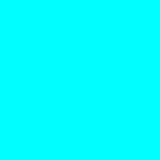

{'instruction': 'move up', 'state': [0, 0.1]}


In [3]:
from PIL import Image
from IPython.display import display

example = next(row for row in rows if row["split"] == "test")
display(Image.open(example["image"]).resize((160, 160), resample=Image.Resampling.NEAREST))
print({"instruction": example["instruction"], "state": example["state"]})

### Train, validate and select

Selection minimizes validation original-unit action MSE, including epoch-zero baseline. Test does
not select models. `export/` saves validation best; `latest_export/` saves the last
epoch. Runs retain baseline, epoch checkpoints, optimizer/RNG, environment and provenance.

In [4]:
report = run(cfg)
print(json.dumps({
    "baseline_test": report["baseline_test"]["metrics"],
    "selected_test": report["finetuned_test"]["metrics"],
    "selected_epoch": report["training"]["best_epoch"],
    "completed_epoch": report["training"]["epoch"],
}, indent=2))
assert report["training"]["epoch"] == cfg.training.epochs

{
  "baseline_test": {
    "action_mse": 0.00797790326178074,
    "action_mae": 0.07684151530265808
  },
  "selected_test": {
    "action_mse": 0.006494909711182118,
    "action_mae": 0.06808139979839326
  },
  "selected_epoch": 2,
  "completed_epoch": 2
}


## Checks — Native export, reload and inference

Reload the export, recompute held-out metrics and assert agreement with the training
report. Tiny generated text/actions/states demonstrate interfaces only and must
not be used for business decisions or robot execution.

In [5]:
loaded = VLAModel.load(report["export"])
reloaded_metrics = evaluate(loaded, prepare_data(rows, loaded, cfg, fit=False), cfg, "test")
assert reloaded_metrics["metrics"] == report["finetuned_test"]["metrics"]
prediction = loaded.predict(example["image"], example["instruction"], example["state"])
assert len(prediction["actions"]) == cfg.model.horizon
assert all(len(a) == cfg.model.action_dim for a in prediction["actions"])
print(json.dumps(prediction, indent=2))

{
  "actions": [
    [
      0.07045648247003555,
      0.08611971884965897
    ],
    [
      0.06238237023353577,
      0.0518205463886261
    ]
  ],
  "action_spec": {
    "state_names": [
      "x",
      "y"
    ],
    "state_units": "meters",
    "action_names": [
      "dx",
      "dy"
    ],
    "action_units": "meters",
    "coordinate_frame": "world",
    "control_frequency_hz": 10.0,
    "horizon": 2,
    "action_dim": 2
  }
}


### Strict epoch-boundary recovery

The next cell resumes an already completed run: it is idempotent and performs no
additional training. Interrupted runs use the same entry point and restart from
the latest completed epoch. Configuration, data, source and relevant dependencies
must remain unchanged. Regression tests cover exact interrupted-run recovery.

In [6]:
resumed = run(cfg, resume=cfg.path(cfg.output_dir) / "latest")
assert resumed["training"] == report["training"]
print({"resume_epoch": resumed["training"]["epoch"], "history_unchanged": True})

{'resume_epoch': 2, 'history_unchanged': True}


### Offline publication preview

Validate the inference-file whitelist and reload without Hub access, repository
creation or upload. Real publication requires explicitly disabling `dry_run` and
checking base licenses, data authorization and model cards.

In [7]:
plan = publish(report["export"], "example/vla-training-guide", dry_run=True)
assert plan["status"] == "dry_run"
names = [item["path"] for item in plan["files"]]
assert not any("training_state" in name for name in names)
print({"status": plan["status"], "inference_files": names})

{'status': 'dry_run', 'inference_files': ['README.md', 'action_head.safetensors', 'advai_metadata.json', 'encoder/config.json', 'encoder/model.safetensors', 'encoder/processor_config.json', 'encoder/tokenizer.json', 'encoder/tokenizer_config.json']}


## Next Steps

- [Full guide](../../docs/vla.md): fields, inference JSON, methods and limitations.
- [Configurations](../../configs/vla/README.md): smoke and supported base/fine-tuning templates.
- Validate smoke first. Real model-aware validation loads weights and needs enough hardware memory; use a new output directory for changed data/settings.
- Measure closed-loop success and enforce action bounds; offline MSE is not a robot-safety guarantee. The pinned CLIP template initializes the action head randomly.

CPU smoke and export reload have been executed. CUDA/MPS, large real-model training
and real robotics/video capability are outside this notebook's validation scope.